In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Base directory: Auspify_Internship (fixed path)
base_dir = r"C:\Users\Lenovo\Downloads\Auspify_Internship"

# Task 4 folders
task4_dir = os.path.join(base_dir, "Task_4_TV_vs_Movies_Analysis")
vis_dir = os.path.join(task4_dir, "visualizations")
reports_dir = os.path.join(task4_dir, "reports")

os.makedirs(vis_dir, exist_ok=True)
os.makedirs(reports_dir, exist_ok=True)

# Cleaned dataset path directly from Task 1
dataset_path = os.path.join(
    base_dir, "Task_1_Netflix_Data_Cleaning", "output", "netflix_cleaned.csv"
)

df = pd.read_csv(dataset_path)

print("Dataset Loaded Successfully for Task 4!")
print(f"Total Rows: {len(df)}")
df[["type", "title", "release_year", "duration"]].head(3)

Dataset Loaded Successfully for Task 4!
Total Rows: 8790


,type,title,release_year,duration
0,Movie,Dick Johnson Is Dead,2020,90 min
1,TV Show,Ganglands,2021,1 Season
2,TV Show,Midnight Mass,2021,1 Season


Distribution Count:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Percentage Split:
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


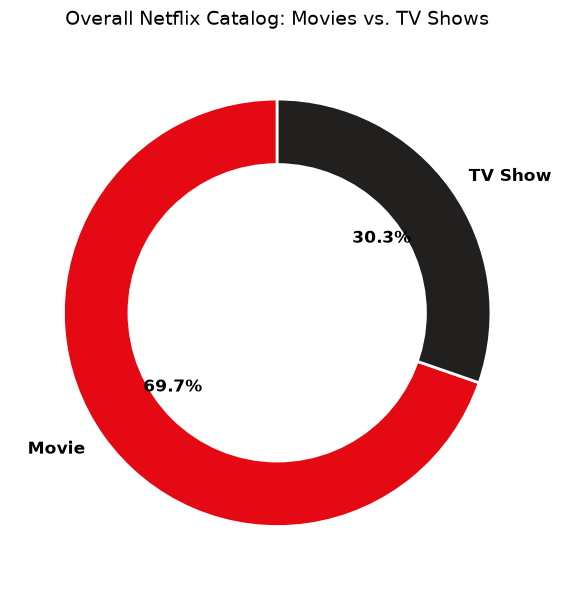

Chart 1 saved at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_4_TV_vs_Movies_Analysis\visualizations\movies_vs_tv_distribution.png


In [3]:
# Format distribution count aur percentage
type_counts = df['type'].value_counts()
type_percentage = (df['type'].value_counts(normalize=True) * 100).round(2)

print("Distribution Count:")
print(type_counts)
print("\nPercentage Split:")
print(type_percentage)

# Visual 1: Donut Chart for Movies vs TV Shows Share
colors = ['#E50914', '#221F1F']
plt.figure(figsize=(6, 6))
plt.pie(
    type_counts, 
    labels=type_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors, 
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'weight': 'bold'}
)

# Centre white circle to create Donut hole
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Overall Netflix Catalog: Movies vs. TV Shows', fontsize=14, pad=15)
plt.tight_layout()

# Save Visual 1
v1_path = os.path.join(vis_dir, 'movies_vs_tv_distribution.png')
plt.savefig(v1_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Chart 1 saved at: {v1_path}")

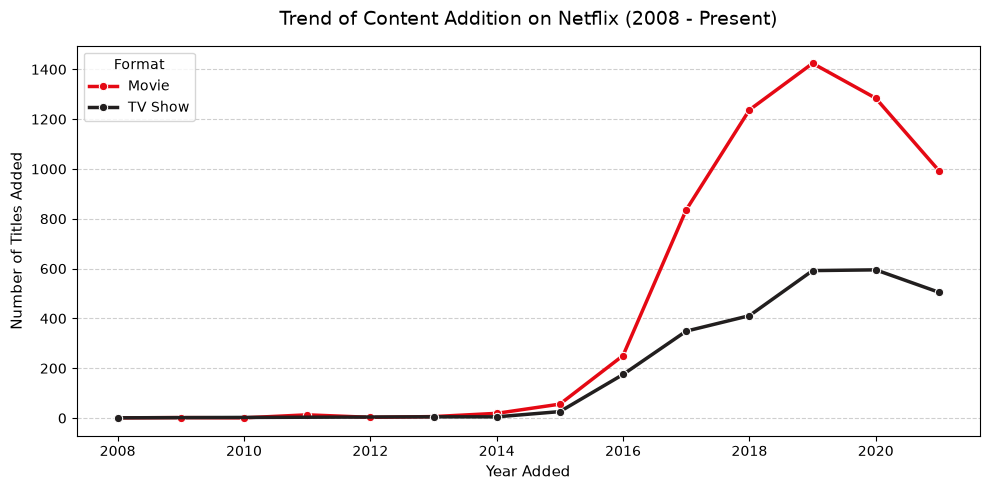

Chart 2 saved at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_4_TV_vs_Movies_Analysis\visualizations\content_trend_by_year.png


In [4]:
# Date added se year extract karna aur filter karna
df['year_added'] = pd.to_datetime(df['date_added']).dt.year

# 2008 ke baad ka trend dekhte hain (Netflix streaming era)
trend_df = (
    df[df['year_added'] >= 2008]
    .groupby(['year_added', 'type'])
    .size()
    .reset_index(name='count')
)

# Visual 2: Line Plot for Trend over Time
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=trend_df,
    x='year_added',
    y='count',
    hue='type',
    palette=['#E50914', '#221F1F'],
    marker='o',
    linewidth=2.5,
)

plt.title('Trend of Content Addition on Netflix (2008 - Present)', fontsize=14, pad=15)
plt.xlabel('Year Added', fontsize=11)
plt.ylabel('Number of Titles Added', fontsize=11)
plt.legend(title='Format')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Save Visual 2
v2_path = os.path.join(vis_dir, 'content_trend_by_year.png')
plt.savefig(v2_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Chart 2 saved at: {v2_path}')

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22716\4272617877.py:3: SyntaxWarning: invalid escape sequence '\d'
  movies_df['duration_min'] = movies_df['duration'].str.extract('(\d+)').astype(float)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22716\4272617877.py:6: SyntaxWarning: invalid escape sequence '\d'
  tv_df['seasons'] = tv_df['duration'].str.extract('(\d+)').astype(float)


Movie Duration Stats (in Minutes):
count    6126.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0
Name: duration_min, dtype: float64

TV Show Seasons Stats:
count    2664.0
mean        1.8
std         1.6
min         1.0
25%         1.0
50%         1.0
75%         2.0
max        17.0
Name: seasons, dtype: float64


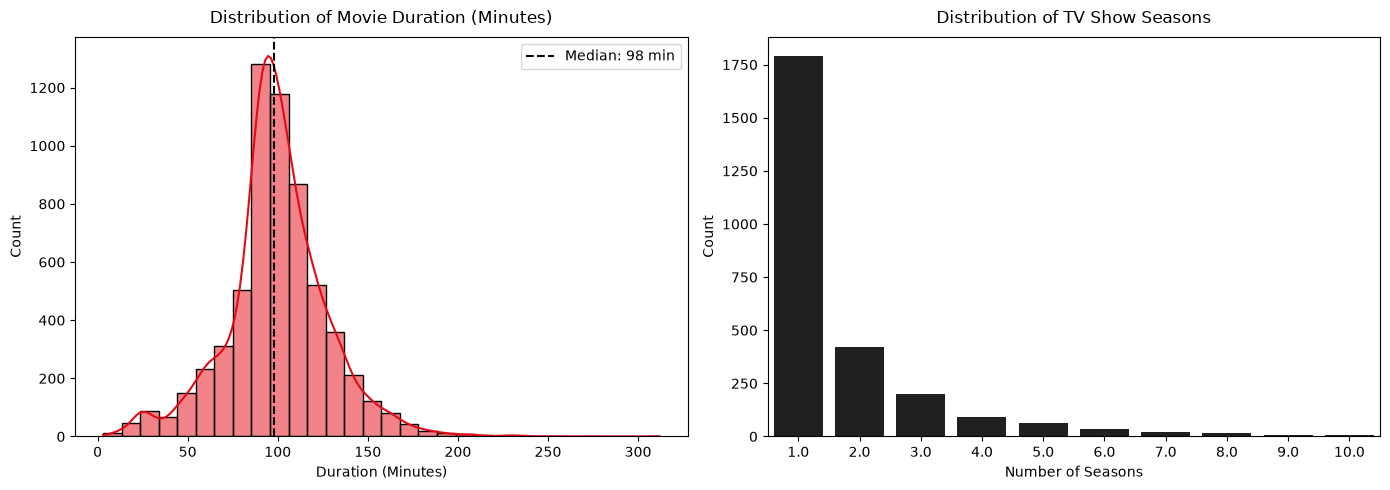

Chart 3 saved at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_4_TV_vs_Movies_Analysis\visualizations\duration_analysis.png


In [5]:
# Duration column se numbers extract karna
movies_df = df[df['type'] == 'Movie'].copy()
movies_df['duration_min'] = movies_df['duration'].str.extract('(\d+)').astype(float)

tv_df = df[df['type'] == 'TV Show'].copy()
tv_df['seasons'] = tv_df['duration'].str.extract('(\d+)').astype(float)

print("Movie Duration Stats (in Minutes):")
print(movies_df['duration_min'].describe().round(1))
print("\nTV Show Seasons Stats:")
print(tv_df['seasons'].describe().round(1))

# Visual 3: Side-by-side Duration Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Movie Duration Distribution (Histogram + KDE)
sns.histplot(movies_df['duration_min'], kde=True, ax=axes[0], color='#E50914', bins=30)
axes[0].set_title('Distribution of Movie Duration (Minutes)', fontsize=12, pad=10)
axes[0].set_xlabel('Duration (Minutes)', fontsize=10)
axes[0].set_ylabel('Count', fontsize=10)
axes[0].axvline(movies_df['duration_min'].median(), color='black', linestyle='--', label=f"Median: {int(movies_df['duration_min'].median())} min")
axes[0].legend()

# Subplot 2: TV Show Seasons Count (Countplot)
sns.countplot(data=tv_df, x='seasons', ax=axes[1], color='#221F1F')
axes[1].set_title('Distribution of TV Show Seasons', fontsize=12, pad=10)
axes[1].set_xlabel('Number of Seasons', fontsize=10)
axes[1].set_ylabel('Count', fontsize=10)
axes[1].set_xlim(-0.5, 9.5)  # Focus on Season 1 to 10

plt.tight_layout()

# Save Visual 3
v3_path = os.path.join(vis_dir, 'duration_analysis.png')
plt.savefig(v3_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Chart 3 saved at: {v3_path}")

In [6]:
report_path = os.path.join(reports_dir, 'tv_vs_movies_summary.txt')

summary_text = f"""Auspify Technologies - Task 4: TV Shows vs. Movies Statistical Comparison
================================================================================

1. Catalog Proportion:
   - Movies: {type_counts.get('Movie', 0)} ({type_percentage.get('Movie', 0)}%)
   - TV Shows: {type_counts.get('TV Show', 0)} ({type_percentage.get('TV Show', 0)}%)
   - Key Insight: Netflix catalog is predominantly movie-heavy (approx. 70% share).

2. Temporal Trend (2008 - Present):
   - Movie additions peaked sharply around 2019.
   - TV Shows maintain a steady, resilient growth rate supporting high subscriber retention.

3. Duration Statistics:
   - Movies:
     * Mean Duration: {movies_df['duration_min'].mean():.1f} minutes
     * Median Duration: {movies_df['duration_min'].median():.0f} minutes
     * Standard Deviation: {movies_df['duration_min'].std():.1f} minutes
   - TV Shows:
     * Overwhelming majority consist of Season 1 only (~67%), highlighting rapid series experimentation.

Generated Visualizations:
- visualizations/movies_vs_tv_distribution.png
- visualizations/content_trend_by_year.png
- visualizations/duration_analysis.png
"""

with open(report_path, 'w') as f:
  f.write(summary_text)

print(f"Report generated successfully at: {report_path}")

Report generated successfully at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_4_TV_vs_Movies_Analysis\reports\tv_vs_movies_summary.txt
